# 7. Model Training — XGBoost
Model thứ 2 trong chuỗi so sánh. Train + đánh giá qua Leave-One-Patient-Out (40 fold, ranh giới đã chốt ở bước preprocessing), lưu model từng fold vào `model/checkpoints/xgboost/`, và ghi kết quả vào cùng bảng so sánh chung `model/results/cv_results.csv` để đối chiếu với LightGBM.

## 7.0 Import & cấu hình

In [1]:
import pandas as pd
import numpy as np
import json
import os
import time
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns

CHECKPOINT_DIR = "../data/checkpoints"
MODEL_DIR = "checkpoints/xgboost"
RESULTS_PATH = "results/cv_results.csv"   
MODEL_NAME = "xgboost"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

RISK_ORDER = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3}
CLASS_NAMES = ["Normal", "Watch", "Alert", "Critical"]
RANDOM_STATE = 42

## 7.1 Load checkpoint từ bước preprocessing

In [2]:
dev_df = pd.read_parquet(f"{CHECKPOINT_DIR}/dev_df.parquet")
test_df = pd.read_parquet(f"{CHECKPOINT_DIR}/test_df.parquet")
manifest = json.load(open(f"{CHECKPOINT_DIR}/split_manifest.json"))

FEATURE_COLS = manifest["feature_cols"]
TARGET_COL = manifest["target_col"]
N_FOLDS = manifest["n_folds"]

print(f"dev_df: {dev_df.shape}, test_df: {test_df.shape}, n_folds={N_FOLDS}")

dev_df: (69409, 48), test_df: (13094, 47), n_folds=40


## 7.2 Encode feature & chuẩn bị X/y

In [3]:
def encode_features(d):
    d = d.copy()
    d["risk_level"] = d["risk_level"].map(RISK_ORDER).astype(int)
    return d

dev_enc = encode_features(dev_df)
X_dev = dev_enc[FEATURE_COLS]
y_dev = dev_enc[TARGET_COL].map(RISK_ORDER).astype(int)
fold_id = dev_enc["fold_id"].astype(int)

## 7.3 Hàm ghi kết quả vào bảng so sánh chung
Tái sử dụng nguyên hàm từ notebook LightGBM để đảm bảo `cv_results.csv` có cùng schema, so sánh trực tiếp được giữa các model.

In [4]:
def log_fold_result(results_path, model_name, fold_id, n_val, train_seconds, y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2, 3], zero_division=0
    )
    row = {
        "model_name": model_name,
        "fold_id": fold_id,
        "n_val": n_val,
        "train_seconds": round(train_seconds, 2),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }
    for i, cls in enumerate(CLASS_NAMES):
        row[f"precision_{cls}"] = precision[i]
        row[f"recall_{cls}"] = recall[i]
        row[f"f1_{cls}"] = f1[i]
        row[f"support_{cls}"] = support[i]

    df_row = pd.DataFrame([row])
    header = not os.path.exists(results_path)
    df_row.to_csv(results_path, mode="a", header=header, index=False)
    return row

## 7.4 Vòng lặp LOPO: train + lưu model + ghi kết quả

In [5]:
XGB_PARAMS = dict(
    objective="multi:softmax", num_class=4,
    n_estimators=500, learning_rate=0.05, max_depth=6,
    tree_method="hist", eval_metric="mlogloss",
    early_stopping_rounds=30,
    random_state=RANDOM_STATE, verbosity=0,
)

oof_pred = np.full(len(dev_enc), -1)

for k in range(N_FOLDS):
    tr_mask = fold_id != k
    va_mask = fold_id == k

    X_tr, y_tr = X_dev[tr_mask], y_dev[tr_mask]
    X_va, y_va = X_dev[va_mask], y_dev[va_mask]

    classes = np.unique(y_tr)
    weights = compute_class_weight("balanced", classes=classes, y=y_tr)
    sample_weight = y_tr.map(dict(zip(classes, weights)))

    t0 = time.time()
    model = xgb.XGBClassifier(**XGB_PARAMS)
    model.fit(
        X_tr, y_tr, sample_weight=sample_weight,
        eval_set=[(X_va, y_va)],
        verbose=False,
    )
    train_seconds = time.time() - t0

    pred = model.predict(X_va)
    oof_pred[va_mask.values] = pred

    model.get_booster().save_model(f"{MODEL_DIR}/fold_{k}.json")
    result_row = log_fold_result(RESULTS_PATH, MODEL_NAME, k, va_mask.sum(), train_seconds, y_va, pred)

    print(f"Fold {k}: macro_f1={result_row['macro_f1']:.3f}, "
          f"recall_Critical={result_row['recall_Critical']:.3f}, "
          f"({train_seconds:.1f}s) — đã lưu model + ghi kết quả")

Fold 0: macro_f1=0.311, recall_Critical=0.000, (5.9s) — đã lưu model + ghi kết quả
Fold 1: macro_f1=0.379, recall_Critical=0.000, (10.1s) — đã lưu model + ghi kết quả
Fold 2: macro_f1=0.488, recall_Critical=0.000, (8.5s) — đã lưu model + ghi kết quả
Fold 3: macro_f1=0.299, recall_Critical=0.000, (21.9s) — đã lưu model + ghi kết quả
Fold 4: macro_f1=0.363, recall_Critical=0.067, (26.7s) — đã lưu model + ghi kết quả
Fold 5: macro_f1=0.423, recall_Critical=0.000, (35.5s) — đã lưu model + ghi kết quả
Fold 6: macro_f1=0.733, recall_Critical=0.799, (7.2s) — đã lưu model + ghi kết quả
Fold 7: macro_f1=0.370, recall_Critical=0.015, (12.5s) — đã lưu model + ghi kết quả
Fold 8: macro_f1=0.416, recall_Critical=0.000, (14.9s) — đã lưu model + ghi kết quả
Fold 9: macro_f1=0.489, recall_Critical=0.000, (13.8s) — đã lưu model + ghi kết quả
Fold 10: macro_f1=0.467, recall_Critical=0.000, (9.7s) — đã lưu model + ghi kết quả
Fold 11: macro_f1=0.441, recall_Critical=0.000, (16.3s) — đã lưu model + ghi kế

## 7.5 Xem lại kết quả XGBoost vừa ghi (đọc lại từ file chung)

In [6]:
all_results = pd.read_csv(RESULTS_PATH)
xgb_results = all_results[all_results["model_name"] == MODEL_NAME]

print("Macro-F1 trung bình ± std:", xgb_results["macro_f1"].mean().round(3), "±", xgb_results["macro_f1"].std().round(3))
n_patients_with_critical = (xgb_results["support_Critical"] > 0).sum()
n_detected = ((xgb_results["support_Critical"] > 0) & (xgb_results["recall_Critical"] > 0)).sum()
print(f"Số bệnh nhân có Critical: {n_patients_with_critical}, trong đó model bắt được ít nhất 1 ca: {n_detected}")

xgb_results[["fold_id", "n_val", "macro_f1", "support_Critical", "recall_Critical", "precision_Critical", "recall_Alert", "precision_Alert"]]

Macro-F1 trung bình ± std: 0.419 ± 0.112
Số bệnh nhân có Critical: 29, trong đó model bắt được ít nhất 1 ca: 9


,fold_id,n_val,macro_f1,support_Critical,recall_Critical,precision_Critical,recall_Alert,precision_Alert
40,0,2113,0.310894,3,0.000000,0.000000,0.234742,0.182482
41,1,2851,0.379250,1,0.000000,0.000000,0.261111,0.129834
42,2,2308,0.488181,4,0.000000,0.000000,0.620112,0.474359
43,0,2113,0.310894,3,0.000000,0.000000,0.234742,0.182482
44,1,2851,0.379250,1,0.000000,0.000000,0.261111,0.129834
45,2,2308,0.488181,4,0.000000,0.000000,0.620112,0.474359
46,3,2785,0.298832,2,0.000000,0.000000,0.000000,0.000000
47,4,2630,0.362711,45,0.066667,0.500000,0.016667,0.014085
48,5,2569,0.423165,0,0.000000,0.000000,0.000000,0.000000
49,6,971,0.732526,581,0.798623,0.845173,0.518987,0.394231


## 7.6 Confusion matrix OOF — trực quan hoá

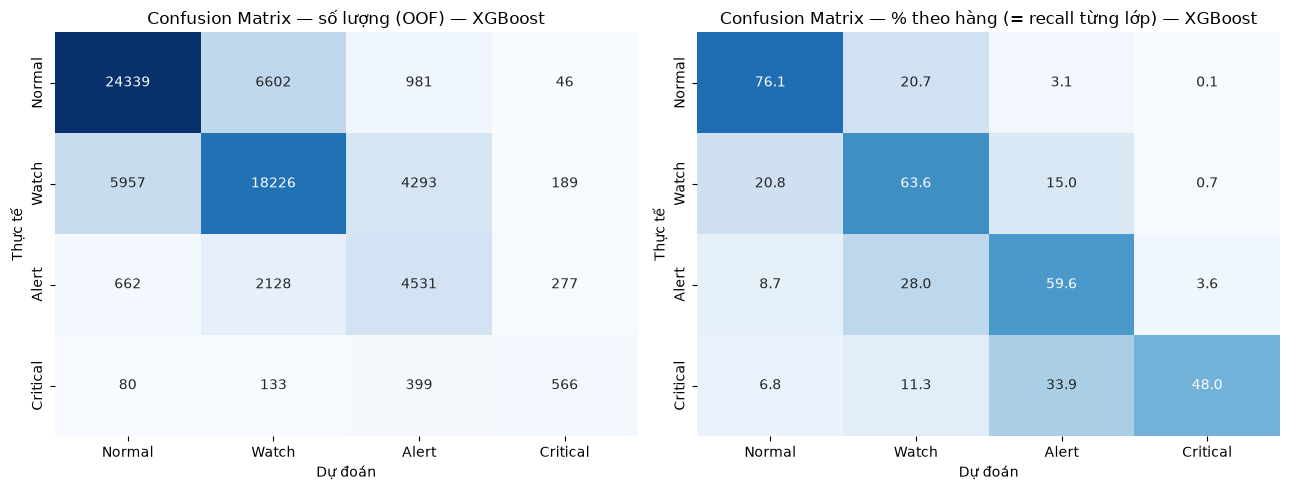

In [7]:
cm = confusion_matrix(y_dev, oof_pred, labels=[0, 1, 2, 3])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], cbar=False)
axes[0].set_title("Confusion Matrix — số lượng (OOF) — XGBoost")
axes[0].set_xlabel("Dự đoán"); axes[0].set_ylabel("Thực tế")

sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], cbar=False, vmin=0, vmax=100)
axes[1].set_title("Confusion Matrix — % theo hàng (= recall từng lớp) — XGBoost")
axes[1].set_xlabel("Dự đoán"); axes[1].set_ylabel("Thực tế")

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/confusion_matrix.png", dpi=120)
plt.show()

## 7.7 Feature importance — bar chart

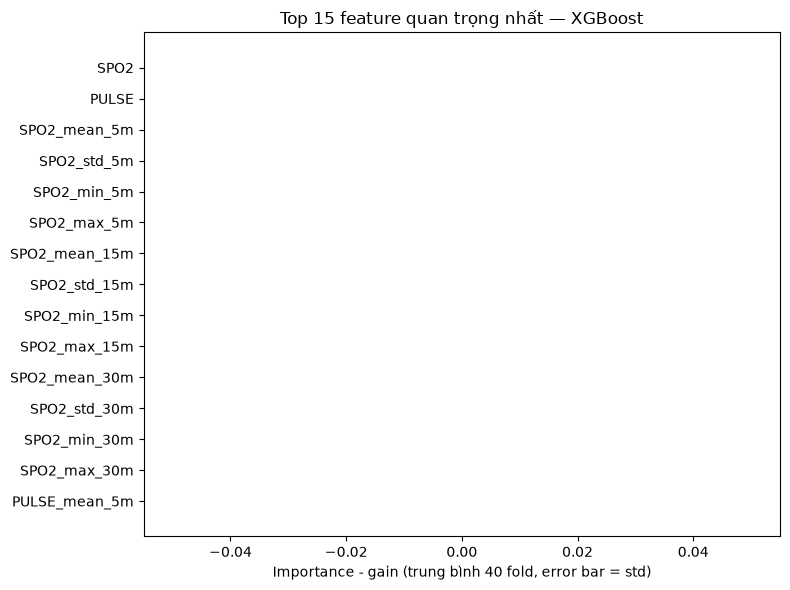

In [8]:
importances = []
for k in range(N_FOLDS):
    booster = xgb.Booster()
    booster.load_model(f"{MODEL_DIR}/fold_{k}.json")
    score_dict = booster.get_score(importance_type="gain")
    importances.append([score_dict.get(f"f{i}", 0.0) for i in range(len(FEATURE_COLS))])

importance_df = pd.DataFrame(np.array(importances).T, index=FEATURE_COLS,
                              columns=[f"fold_{k}" for k in range(N_FOLDS)])
importance_df["mean"] = importance_df.mean(axis=1)
importance_df["std"] = importance_df.iloc[:, :N_FOLDS].std(axis=1)

top15 = importance_df.sort_values("mean", ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15["mean"][::-1], xerr=top15["std"][::-1], color="#dd8452")
plt.xlabel(f"Importance - gain (trung bình {N_FOLDS} fold, error bar = std)")
plt.title("Top 15 feature quan trọng nhất — XGBoost")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/feature_importance.png", dpi=120)
plt.show()